# Prediction of *CHANGE* in 5-day Volatility

In [ ]:
import pandas as pd

snp_df = pd.read_csv(r"C:\Users\email\Downloads\SNP500 - Copy.csv")

snp_df["Date"] = pd.to_datetime(
    snp_df["Date"],
    format="%m/%d/%Y"
)

snp_df = snp_df.rename(columns={"Close/Last": "Close"})
snp_df = snp_df.iloc[::-1].reset_index(drop=True)
snp_df = snp_df.set_index('Date')


import numpy as np

# Log returns (forward-looking because dates are descending)
snp_df['log_return'] = np.log(snp_df['Close'] / snp_df['Close'].shift(1))

# 20-day rolling volatility of log_return
snp_df['5d_vol'] = snp_df['log_return'].rolling(window=5).std()
snp_df['delta_5d_vol'] = snp_df['5d_vol'].diff()



snp_df = snp_df.drop(columns=['Close', 'Volume', 'Open', 'High', 'Low'])
print(snp_df.tail())

            log_return    5d_vol  delta_5d_vol
Date                                          
2021-01-04   -0.013708  0.008549      0.004623
2021-01-05    0.006864  0.008145     -0.000405
2021-01-06    0.005961  0.008543      0.000399
2021-01-07    0.014748  0.010512      0.001969
2021-01-08    0.005682  0.010535      0.000022


# Data Preparation for Lagging, Normalizing, and Tensors

In [63]:
cols = ["log_return", "5d_vol"]
max_lag = 10

for col in cols:
    for lag in range(1, max_lag + 1):
        snp_df[f"{col}_lag_{lag}"] = snp_df[col].shift(lag)


snp_df = snp_df.dropna().reset_index(drop=True)

print(snp_df.head())

   log_return    5d_vol  delta_5d_vol  log_return_lag_1  log_return_lag_2  \
0   -0.002402  0.003376      0.000158          0.001948         -0.004706   
1   -0.003682  0.003666      0.000290         -0.002402          0.001948   
2    0.000501  0.002811     -0.000855         -0.003682         -0.002402   
3    0.005991  0.003813      0.001002          0.000501         -0.003682   
4    0.003162  0.003966      0.000153          0.005991          0.000501   

   log_return_lag_3  log_return_lag_4  log_return_lag_5  log_return_lag_6  \
0          0.003709          0.000544          0.001951          0.007523   
1         -0.004706          0.003709          0.000544          0.001951   
2          0.001948         -0.004706          0.003709          0.000544   
3         -0.002402          0.001948         -0.004706          0.003709   
4         -0.003682         -0.002402          0.001948         -0.004706   

   log_return_lag_7  ...  5d_vol_lag_1  5d_vol_lag_2  5d_vol_lag_3  \
0   

Note to self: Final X tensor dimensions should be (no. of obs, no. of time lags, no. of variables).

In [64]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler


y = snp_df["delta_5d_vol"].values.astype(np.float32)
numeric_cols = [col for col in snp_df.columns if "lag" in col.lower()]
X_numeric_raw = snp_df[numeric_cols].values.astype(np.float32)


# Chronological Split (Slicing by index)
# shuffle=False is the key here
X_numeric_train_2d, X_numeric_temp_2d, y_train, y_temp = train_test_split(
    X_numeric_raw, y, test_size=0.3, shuffle=False
)

# Split the 30% "temp" into half (15% Val, 15% Test)
X_numeric_val_2d, X_numeric_test_2d, y_val, y_test = train_test_split(
    X_numeric_temp_2d, y_temp, test_size=0.5, shuffle=False
)


# Scale in 2D (Fit only on Training data to avoid data leakage)
scaler = StandardScaler()
X_numeric_train_scaled = scaler.fit_transform(X_numeric_train_2d)
X_numeric_val_scaled   = scaler.transform(X_numeric_val_2d)
X_numeric_test_scaled  = scaler.transform(X_numeric_test_2d)


def reshape_to_sequences(data, num_features=5, num_lags=20):
    """
    Reshape 2D scaled array to 3D LSTM input:
    Input: 2D array (samples, features*num_lags)
    Output: 3D array (samples, num_lags, num_features)
    """
    # Step 1: reshape to (samples, num_lags, num_features)
    data_reshaped = data.reshape(-1, num_lags, num_features)
    
    # Step 2: flip lags so that lag_1 is first
    # Make a copy to avoid negative strides
    data_reshaped = data_reshaped[:, ::-1, :].copy()
    
    return data_reshaped



X_numeric_train = reshape_to_sequences(X_numeric_train_scaled, num_features=2, num_lags=10)
X_numeric_val   = reshape_to_sequences(X_numeric_val_scaled, num_features=2, num_lags=10)
X_numeric_test  = reshape_to_sequences(X_numeric_test_scaled, num_features=2, num_lags=10)


# Sanity check for dimensions 
print(X_numeric_train.shape)  # e.g., torch.Size([num_train_samples, 20, 5])
print(X_numeric_val.shape)
print(X_numeric_test.shape)
print(y_train.shape)
print(y_val.shape)
print(y_test.shape)



(723, 10, 2)
(155, 10, 2)
(156, 10, 2)
(723,)
(155,)
(156,)


# Data Loader, Iterator

In [65]:
import torch

# Features
X_train_tensor = torch.tensor(X_numeric_train, dtype=torch.float32)
X_val_tensor   = torch.tensor(X_numeric_val, dtype=torch.float32)
X_test_tensor  = torch.tensor(X_numeric_test, dtype=torch.float32)

# Targets (unsqueeze to get shape [samples, 1] for regression)
y_train_tensor = torch.tensor(y_train, dtype=torch.float32)
y_val_tensor   = torch.tensor(y_val, dtype=torch.float32)
y_test_tensor  = torch.tensor(y_test, dtype=torch.float32)


from torch.utils.data import Dataset

class TimeSeriesDataset(Dataset):
    def __init__(self, X, y):
        self.X = X
        self.y = y
        
    def __len__(self):
        return len(self.y)
    
    def __getitem__(self, idx):
        return self.X[idx], self.y[idx]


train_dataset = TimeSeriesDataset(X_train_tensor, y_train_tensor)
val_dataset   = TimeSeriesDataset(X_val_tensor, y_val_tensor)
test_dataset  = TimeSeriesDataset(X_test_tensor, y_test_tensor)


from torch.utils.data import DataLoader

batch_size = 32

train_loader = DataLoader(train_dataset, batch_size=batch_size, shuffle=False)
val_loader   = DataLoader(val_dataset, batch_size=batch_size, shuffle=False)
test_loader  = DataLoader(test_dataset, batch_size=batch_size, shuffle=False)

# Moden and Instantiation

In [66]:
import torch
import torch.nn as nn

class NumericLSTMRegressor(nn.Module):
    def __init__(self, num_features, hidden_dims=[16, 8], dropout=0.2):
        """
        num_features : int - number of numeric features per timestep
        hidden_dims  : list[int] - number of neurons per LSTM layer
        dropout      : float - dropout rate between LSTM layers
        """
        super().__init__()
        
        self.num_layers = len(hidden_dims)
        self.hidden_dims = hidden_dims
        
        # Create a stack of LSTM layers
        lstm_layers = []
        input_dim = num_features
        for h_dim in hidden_dims:
            lstm_layers.append(
                nn.LSTM(
                    input_size=input_dim,
                    hidden_size=h_dim,
                    batch_first=True,
                    bidirectional=False
                )
            )
            input_dim = h_dim  # next LSTM input = previous LSTM hidden size
        
        self.lstm_layers = nn.ModuleList(lstm_layers)
        self.dropout = nn.Dropout(dropout)
        
        # Final regression head
        self.fc = nn.Linear(hidden_dims[-1], 1)
        
    def forward(self, x):
        # x shape: (batch_size, seq_len, num_features)
        output = x
        for lstm in self.lstm_layers:
            output, (h_n, c_n) = lstm(output)
            output = self.dropout(output)  # apply dropout after each LSTM layer
        
        # Take the last timestep's output for regression
        # output shape: (batch_size, seq_len, hidden_size) -> take last timestep
        last_output = output[:, -1, :]  # shape: (batch_size, hidden_size)
        
        return self.fc(last_output).squeeze(1)  # (batch_size,)



model = NumericLSTMRegressor(
    num_features=2,
    hidden_dims=[64, 128],
    dropout=0.2
)

# Move model to GPU if available
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
model.to(device)

print(model)

NumericLSTMRegressor(
  (lstm_layers): ModuleList(
    (0): LSTM(2, 64, batch_first=True)
    (1): LSTM(64, 128, batch_first=True)
  )
  (dropout): Dropout(p=0.2, inplace=False)
  (fc): Linear(in_features=128, out_features=1, bias=True)
)


# Optimizer and Criterion

In [67]:
optimizer = torch.optim.Adam(model.parameters(), lr=1e-3)
criterion = nn.MSELoss()

# Training

In [68]:
def train_epoch(model, loader, optimizer, criterion, device):
    model.train()
    epoch_loss = 0
    
    for batch in loader:
        x_num, y = [b.to(device) for b in batch]
        
        optimizer.zero_grad()
        predictions = model(x_num)  # numeric-only LSTM forward pass
        
        loss = criterion(predictions, y)
        loss.backward()
        optimizer.step()
        
        epoch_loss += loss.item()
        
    return epoch_loss / len(loader)


# Evaluation

In [69]:
def evaluate(model, loader, criterion, device):
    """
    Evaluate a numeric-only LSTM on a given DataLoader.

    Returns:
        avg_loss: float
        all_predictions: tensor of shape (num_samples,)
        all_targets: tensor of shape (num_samples,)
    """
    model.eval()  # set to eval mode
    epoch_loss = 0
    all_predictions = []
    all_targets = []

    with torch.no_grad():
        for batch in loader:
            x_num, y = [b.to(device) for b in batch]  # numeric-only
            predictions = model(x_num)
            
            loss = criterion(predictions, y)
            epoch_loss += loss.item()
            
            all_predictions.append(predictions.cpu())
            all_targets.append(y.cpu())
    
    # Concatenate all predictions and targets
    all_predictions = torch.cat(all_predictions, dim=0)
    all_targets = torch.cat(all_targets, dim=0)
    
    avg_loss = epoch_loss / len(loader)
    
    return avg_loss, all_predictions, all_targets


# Timer

In [70]:
import time

def epoch_time(start_time, end_time):
    elapsed_time = end_time - start_time
    elapsed_mins = int(elapsed_time / 60)
    elapsed_secs = int(elapsed_time - (elapsed_mins * 60))
    return elapsed_mins, elapsed_secs

# Training

In [71]:
import torch
import torch.nn as nn
import time
import copy

# Hyperparameters
N_EPOCHS = 100
PATIENCE = 10
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

model.to(DEVICE)
criterion = nn.MSELoss()
optimizer = torch.optim.AdamW(model.parameters(), lr=1e-3)

# Early stopping variables
best_valid_loss = float('inf')
best_model_state = copy.deepcopy(model.state_dict())
epochs_no_improve = 0

train_losses = []
valid_losses = []

# Function to compute R^2
def r2_score_torch(y_true, y_pred):
    ss_res = ((y_true - y_pred) ** 2).sum()
    ss_tot = ((y_true - y_true.mean()) ** 2).sum()
    return 1 - ss_res / ss_tot

for epoch in range(N_EPOCHS):
    start_time = time.time()
    
    # --- Training ---
    model.train()
    epoch_train_loss = 0
    all_train_preds = []
    all_train_targets = []
    
    for batch in train_loader:
        x_num, y = [b.to(DEVICE) for b in batch]
        optimizer.zero_grad()
        predictions = model(x_num)
        loss = criterion(predictions, y)
        loss.backward()
        optimizer.step()
        epoch_train_loss += loss.item()
        
        all_train_preds.append(predictions.detach())
        all_train_targets.append(y.detach())
    
    epoch_train_loss /= len(train_loader)
    train_losses.append(epoch_train_loss)
    
    # Concatenate all predictions and targets
    all_train_preds = torch.cat(all_train_preds, dim=0)
    all_train_targets = torch.cat(all_train_targets, dim=0)
    train_r2 = r2_score_torch(all_train_targets, all_train_preds).item()
    
    # --- Validation ---
    model.eval()
    epoch_valid_loss = 0
    all_val_preds = []
    all_val_targets = []
    
    with torch.no_grad():
        for batch in val_loader:
            x_num, y = [b.to(DEVICE) for b in batch]
            predictions = model(x_num)
            loss = criterion(predictions, y)
            epoch_valid_loss += loss.item()
            
            all_val_preds.append(predictions)
            all_val_targets.append(y)
    
    epoch_valid_loss /= len(val_loader)
    valid_losses.append(epoch_valid_loss)
    
    all_val_preds = torch.cat(all_val_preds, dim=0)
    all_val_targets = torch.cat(all_val_targets, dim=0)
    valid_r2 = r2_score_torch(all_val_targets, all_val_preds).item()
    
    # --- Early Stopping Check ---
    if epoch_valid_loss < best_valid_loss:
        best_valid_loss = epoch_valid_loss
        best_model_state = copy.deepcopy(model.state_dict())
        epochs_no_improve = 0
    else:
        epochs_no_improve += 1
    
    # --- Timer ---
    end_time = time.time()
    epoch_mins, epoch_secs = epoch_time(start_time, end_time)
    
    # --- Print epoch stats ---
    print(f"Epoch {epoch+1:03}/{N_EPOCHS} | "
          f"Train Loss: {epoch_train_loss:.6f} | Train R^2: {train_r2:.4f} | "
          f"Val Loss: {epoch_valid_loss:.6f} | Val R^2: {valid_r2:.4f} | "
          f"Time: {epoch_mins}m {epoch_secs}s")
    
    # --- Print no improvement message ---
    if epochs_no_improve > 0:
        print(f"No improvement for {epochs_no_improve}/{PATIENCE} epochs")
    
    # Stop if no improvement for PATIENCE epochs
    if epochs_no_improve >= PATIENCE:
        print(f"Early stopping triggered after {epoch+1} epochs")
        break

# --- Load best model ---
model.load_state_dict(best_model_state)
print("Best model loaded with validation loss:", best_valid_loss)

Epoch 001/100 | Train Loss: 0.000289 | Train R^2: -53.7464 | Val Loss: 0.000033 | Val R^2: -0.4657 | Time: 0m 0s
Epoch 002/100 | Train Loss: 0.000060 | Train R^2: -10.3357 | Val Loss: 0.000039 | Val R^2: -0.7906 | Time: 0m 0s
No improvement for 1/10 epochs
Epoch 003/100 | Train Loss: 0.000046 | Train R^2: -7.7196 | Val Loss: 0.000043 | Val R^2: -0.9610 | Time: 0m 0s
No improvement for 2/10 epochs
Epoch 004/100 | Train Loss: 0.000037 | Train R^2: -5.9494 | Val Loss: 0.000030 | Val R^2: -0.3458 | Time: 0m 0s
Epoch 005/100 | Train Loss: 0.000027 | Train R^2: -4.0355 | Val Loss: 0.000027 | Val R^2: -0.2519 | Time: 0m 0s
Epoch 006/100 | Train Loss: 0.000026 | Train R^2: -3.9758 | Val Loss: 0.000032 | Val R^2: -0.4769 | Time: 0m 0s
No improvement for 1/10 epochs
Epoch 007/100 | Train Loss: 0.000023 | Train R^2: -3.3692 | Val Loss: 0.000033 | Val R^2: -0.5231 | Time: 0m 0s
No improvement for 2/10 epochs
Epoch 008/100 | Train Loss: 0.000019 | Train R^2: -2.5682 | Val Loss: 0.000027 | Val R^2: 

# Testing

In [72]:
# --- Testing ---
test_loss, test_preds, test_targets = evaluate(model, test_loader, criterion, DEVICE)

print(f"Test Loss: {test_loss:.10f}")

from sklearn.metrics import precision_score, recall_score, r2_score, mean_absolute_error, mean_squared_error

# Convert tensors to numpy arrays
y_true = test_targets.numpy()
y_pred = test_preds.numpy()

# Compute 
r2 = r2_score(y_true, y_pred)
mae = mean_absolute_error(y_true, y_pred)
rmse = np.sqrt(mean_squared_error(y_true, y_pred))


print(f"R²: {r2:.10f}")
print(f"MAE: {mae:.10f}")
print(f"RMSE: {rmse:.10f}")

# --- Directional analysis ---
# Δy = today - yesterday
delta_true = np.diff(y_true)  # Δ true
delta_pred = np.diff(y_pred)  # Δ predicted

# Convert to binary labels: 1 = up, 0 = down (or no change treated as up)
y_true_dir = (delta_true > 0).astype(int)
y_pred_dir = (delta_pred > 0).astype(int)

# Directional accuracy
directional_accuracy = np.mean(y_true_dir == y_pred_dir)
print(f"Directional Accuracy: {directional_accuracy:.4f}")

# Precision & Recall for "up" moves
precision_up = precision_score(y_true_dir, y_pred_dir)
recall_up = recall_score(y_true_dir, y_pred_dir)

# Precision & Recall for "down" moves
# Flip labels: down=1, up=0
precision_down = precision_score(1 - y_true_dir, 1 - y_pred_dir)
recall_down = recall_score(1 - y_true_dir, 1 - y_pred_dir)

print(f"Precision (Up):  {precision_up:.4f}")
print(f"Recall (Up):     {recall_up:.4f}")
print(f"Precision (Down):{precision_down:.4f}")
print(f"Recall (Down):   {recall_down:.4f}")

Test Loss: 0.0000107902
R²: 0.1063023806
MAE: 0.0019294707
RMSE: 0.0033155369
Directional Accuracy: 0.5032
Precision (Up):  0.4815
Recall (Up):     0.5270
Precision (Down):0.5270
Recall (Down):   0.4815


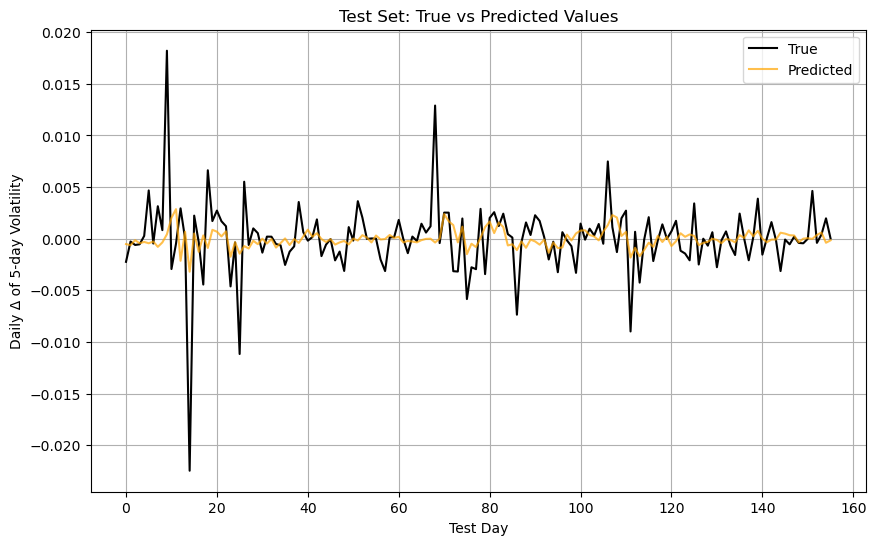

In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 6))
plt.plot(y_true, label='True', color='black')
plt.plot(y_pred, label='Predicted', color='orange', alpha=0.7)
plt.xlabel("Test Day")
plt.ylabel("Daily Δ of 5-day Volatility")
plt.title("Test Set: True vs Predicted Values")
plt.legend()
plt.grid(True)
plt.show()


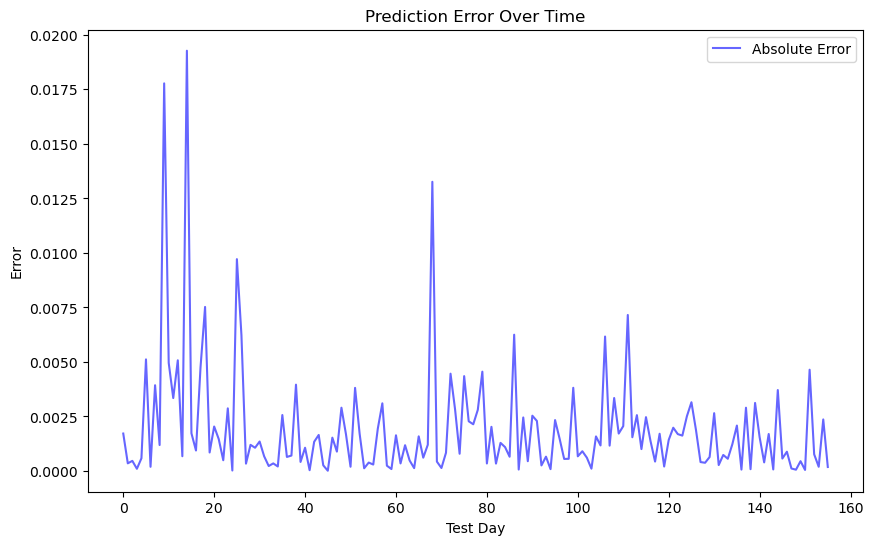

In [74]:
# Compute raw error (prediction - true)
errors = y_pred - y_true

# Optional: absolute error
abs_errors = np.abs(errors)

plt.figure(figsize=(10, 6))
plt.plot(abs_errors, label='Absolute Error', color='blue', alpha=0.6)

plt.title("Prediction Error Over Time")
plt.xlabel("Test Day")
plt.ylabel("Error")
plt.legend()
plt.show()